# Four-channel background estimation with conservative source masking

```python
noise = np.maximum(err, bkg0.background_rms)
threshold = DETECTION_SIGMA * noise
```

The common source mask is still constructed from Hα + [O III].

In [1]:
# =========================================================
# Imports
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import SigmaClip

from photutils.background import (Background2D, MedianBackground, MADStdBackgroundRMS)
from photutils.segmentation import detect_sources
from photutils.utils import circular_footprint

In [2]:
# =========================================================
# Settings
# =========================================================

path = "/Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits"

BOX_SIZE = 100

DETECTION_SIGMA = 3.0
N_PIXELS = 20
DILATION_RADIUS = 4

FILTER_SIZE = (3, 3)
EXCLUDE_PERCENTILE = 50.0

# PHANGS-MUSE DAP line fluxes/errors are stored in
# units of 1e-20 erg s^-1 cm^-2 spaxel^-1.
FLUX_UNIT = 1e-20

# Keep at 1 unless you explicitly want to inflate DAP errors.
ERROR_SCALE = 1.0

In [3]:
# =========================================================
# 1. Read the four line-flux and line-error maps
# =========================================================

extensions = {
    "ha":   ("HA6562_FLUX",   "HA6562_FLUX_ERR"),
    "hb":   ("HB4861_FLUX",   "HB4861_FLUX_ERR"),
    "oiii": ("OIII5006_FLUX", "OIII5006_FLUX_ERR"),
    "nii":  ("NII6583_FLUX",  "NII6583_FLUX_ERR")}

flux_maps = {}
raw_error_maps = {}
headers = {}

with fits.open(path, memmap=True) as hdul:

    for name, (flux_ext, err_ext) in extensions.items():

        flux_maps[name] = (
            np.array(
                hdul[flux_ext].data,
                dtype=np.float32,
                copy=True
            )
            * FLUX_UNIT
        )

        raw_error_maps[name] = (
            np.array(
                hdul[err_ext].data,
                dtype=np.float32,
                copy=True
            )
            * FLUX_UNIT
            * ERROR_SCALE
        )

        headers[name] = hdul[flux_ext].header.copy()

        print(
            name,
            flux_ext,
            "BUNIT =",
            hdul[flux_ext].header.get("BUNIT")
        )

shape = flux_maps["ha"].shape

assert all(
    arr.shape == shape
    for arr in flux_maps.values()
)

assert all(
    arr.shape == shape
    for arr in raw_error_maps.values()
)


ha HA6562_FLUX BUNIT = None
hb HB4861_FLUX BUNIT = None
oiii OIII5006_FLUX BUNIT = None
nii NII6583_FLUX BUNIT = None


In [4]:
# =========================================================
# 2. Per-channel coverage masks
# =========================================================

coverage_masks = {}

for name in flux_maps:

    flux = flux_maps[name]
    err = raw_error_maps[name]

    coverage_masks[name] = (
        ~np.isfinite(flux)
        | ~np.isfinite(err)
        | (err <= 0)
    )


# Pixels usable in all four channels
common_valid = np.logical_and.reduce(
    [
        ~coverage_masks[name]
        for name in flux_maps
    ]
)

print(
    "Fraction valid in all four channels:",
    common_valid.mean()
)


Fraction valid in all four channels: 0.8006768761199016


In [5]:
# =========================================================
# Helper: Background2D
# =========================================================

sigma_clip = SigmaClip(
    sigma=3.0,
    maxiters=10
)


def run_background2d(
    data,
    coverage_mask,
    source_mask=None
):

    return Background2D(
        data,
        box_size=BOX_SIZE,

        mask=source_mask,
        coverage_mask=coverage_mask,
        fill_value=np.nan,

        sigma_clip=sigma_clip,

        bkg_estimator=MedianBackground(),
        bkg_rms_estimator=MADStdBackgroundRMS(),

        filter_size=FILTER_SIZE,
        exclude_percentile=EXCLUDE_PERCENTILE,
    )


## Conservative source-mask construction

The source-detection noise is defined as the larger of the formal DAP error and the local empirical Background2D RMS. This restores the conservative behavior of the earlier notebook.

In [6]:
# =========================================================
# 3. First-pass backgrounds + common source mask
# =========================================================

footprint = circular_footprint(
    radius=DILATION_RADIUS
)

source_mask = np.zeros(
    shape,
    dtype=bool
)

initial_backgrounds = {}


# Use Halpha and [OIII] to find emission-line sources.
#
# We still estimate backgrounds/errors for all four lines,
# but Halpha and [OIII] are used to construct the common
# source mask.
detection_channels = [
    "ha",
    "oiii",
]


for name in detection_channels:

    flux = flux_maps[name]
    err = raw_error_maps[name]
    coverage = coverage_masks[name]


    # -----------------------------------------
    # Initial background estimate
    # -----------------------------------------

    bkg0 = run_background2d(
        flux,
        coverage_mask=coverage,
        source_mask=None,
    )

    initial_backgrounds[name] = (
        bkg0.background
    )


    # -----------------------------------------
    # Background-subtracted image
    # -----------------------------------------

    residual = (
        flux
        - bkg0.background
    )


    # -----------------------------------------
    # CONSERVATIVE noise estimate
    # -----------------------------------------
    #
    # Use whichever is larger:
    #
    # 1. formal DAP measurement uncertainty
    # 2. empirical local RMS measured by Background2D

    noise = np.maximum(
        err,
        bkg0.background_rms
    )


    threshold = (
        DETECTION_SIGMA
        * noise
    )

    threshold = threshold.copy()

    # Do not detect sources outside valid coverage
    threshold[coverage] = np.inf


    # -----------------------------------------
    # Detect sources
    # -----------------------------------------

    segm = detect_sources(
        residual,
        threshold,
        npixels=N_PIXELS,
        mask=coverage,
    )


    # -----------------------------------------
    # Grow mask and add to common source mask
    # -----------------------------------------

    if segm is not None:

        source_mask |= (
            segm.make_source_mask(
                footprint=footprint
            )
        )


# Pixels with no coverage in ANY channel
# should not be interpreted as sources.
all_no_coverage = np.logical_and.reduce(
    [
        coverage_masks[name]
        for name in flux_maps
    ]
)

source_mask[
    all_no_coverage
] = False


print(
    "Source-mask fraction:",
    source_mask.mean()
)


Source-mask fraction: 0.1664598012269566


In [7]:
# =========================================================
# 4. Final diffuse-background maps
# =========================================================

background_maps = {}
residual_rms_maps = {}


for name in flux_maps:

    bkg = run_background2d(
        flux_maps[name],
        coverage_mask=coverage_masks[name],
        source_mask=source_mask,
    )


    background_maps[name] = (
        bkg.background.astype(
            np.float32
        )
    )


    # Diagnostic quantity:
    # empirical scatter remaining around the background
    residual_rms_maps[name] = (
        bkg.background_rms.astype(
            np.float32
        )
    )


In [8]:
# =========================================================
# 5. Smooth observational error maps
# =========================================================
#
# The DAP *_FLUX_ERR maps provide the measurement
# uncertainty used later for synthetic noise.
#
# Background2D is used here to obtain smooth error maps.
# The same source mask prevents bright sources from
# strongly affecting these maps.

error_maps = {}


for name in raw_error_maps:

    err_bkg = run_background2d(
        raw_error_maps[name],
        coverage_mask=coverage_masks[name],
        source_mask=source_mask,
    )


    error_maps[name] = (
        err_bkg.background.astype(
            np.float32
        )
    )


In [9]:
# =========================================================
# 6. Diagnostics
# =========================================================

for name in flux_maps:

    valid = (
        common_valid
        & ~source_mask
        & np.isfinite(background_maps[name])
        & np.isfinite(error_maps[name])
        & (error_maps[name] > 0)
    )


    b = background_maps[name][valid]
    e = error_maps[name][valid]


    print(
        f"\n{name.upper()}"
    )


    print(
        "background 16/50/84 percentiles:",
        np.nanpercentile(
            b,
            [16, 50, 84]
        )
    )


    print(
        "error      16/50/84 percentiles:",
        np.nanpercentile(
            e,
            [16, 50, 84]
        )
    )


    positive = b > 0

    if np.any(positive):

        snr = (
            b[positive]
            / e[positive]
        )

        print(
            "background S/N 16/50/84 percentiles:",
            np.nanpercentile(
                snr,
                [16, 50, 84]
            )
        )



HA
background 16/50/84 percentiles: [8.40284785e-19 1.80765837e-18 6.22869759e-18]
error      16/50/84 percentiles: [1.82281569e-19 2.15665728e-19 3.18409063e-19]
background S/N 16/50/84 percentiles: [ 4.59426893  8.49828148 18.84155151]

HB
background 16/50/84 percentiles: [3.19356777e-19 5.79684399e-19 1.53298444e-18]
error      16/50/84 percentiles: [2.12465929e-19 2.33132868e-19 2.85478194e-19]
background S/N 16/50/84 percentiles: [1.42751517 2.54768956 5.27153652]

OIII
background 16/50/84 percentiles: [2.54731429e-19 4.67190188e-19 9.01357008e-19]
error      16/50/84 percentiles: [2.01337833e-19 2.26135696e-19 2.76326104e-19]
background S/N 16/50/84 percentiles: [1.25517987 2.09477794 3.2443684 ]

NII
background 16/50/84 percentiles: [4.79086285e-19 1.04622280e-18 3.08213577e-18]
error      16/50/84 percentiles: [1.53746797e-19 1.84266152e-19 2.57140415e-19]
background S/N 16/50/84 percentiles: [ 3.07551406  5.69414043 12.17836266]


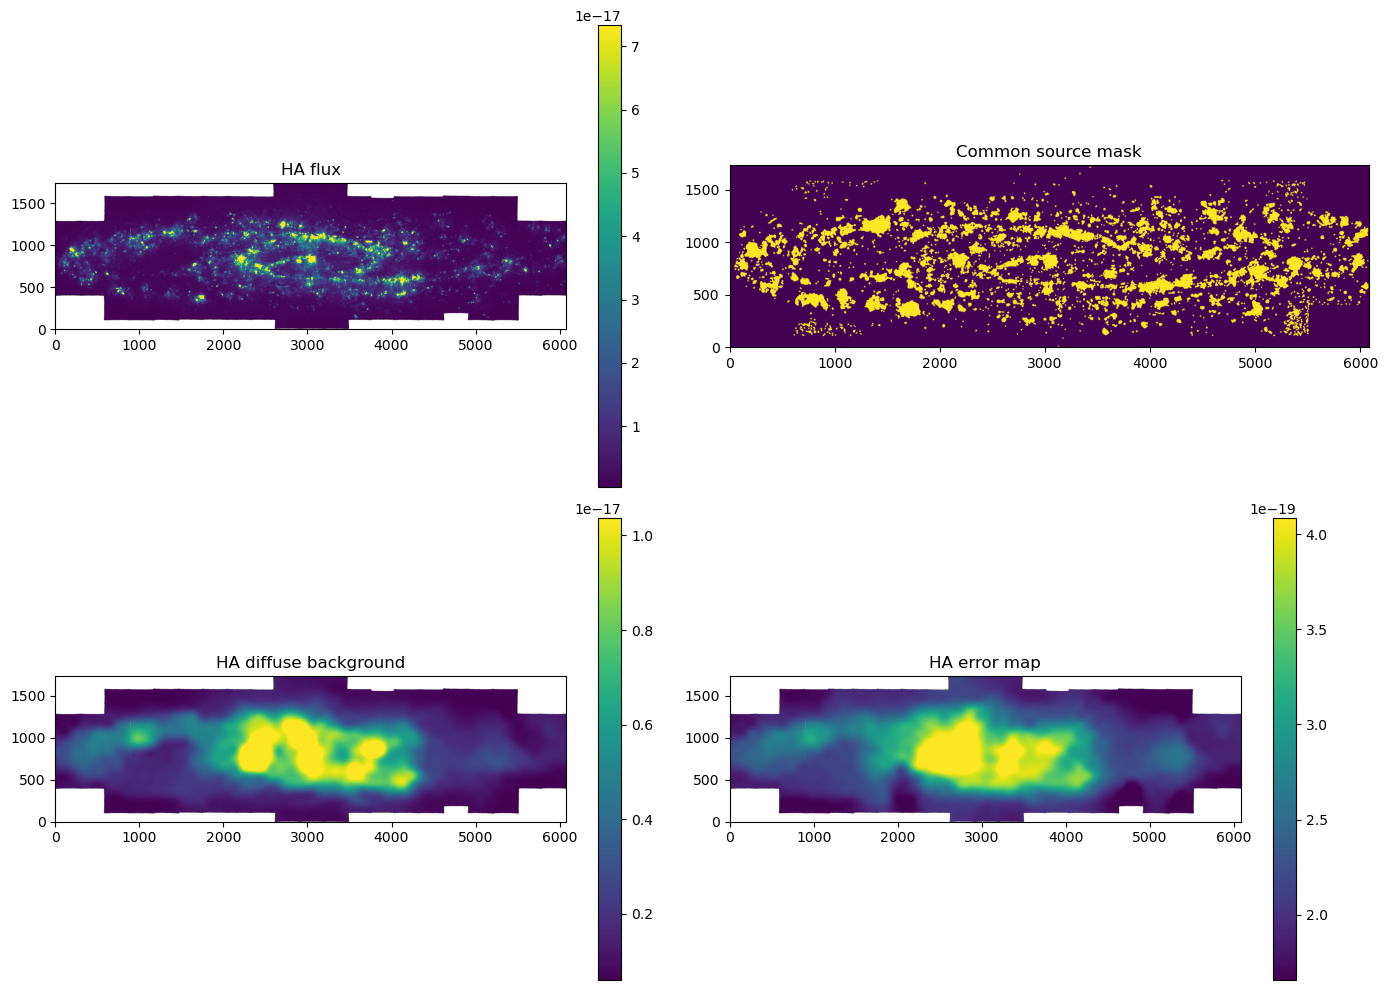

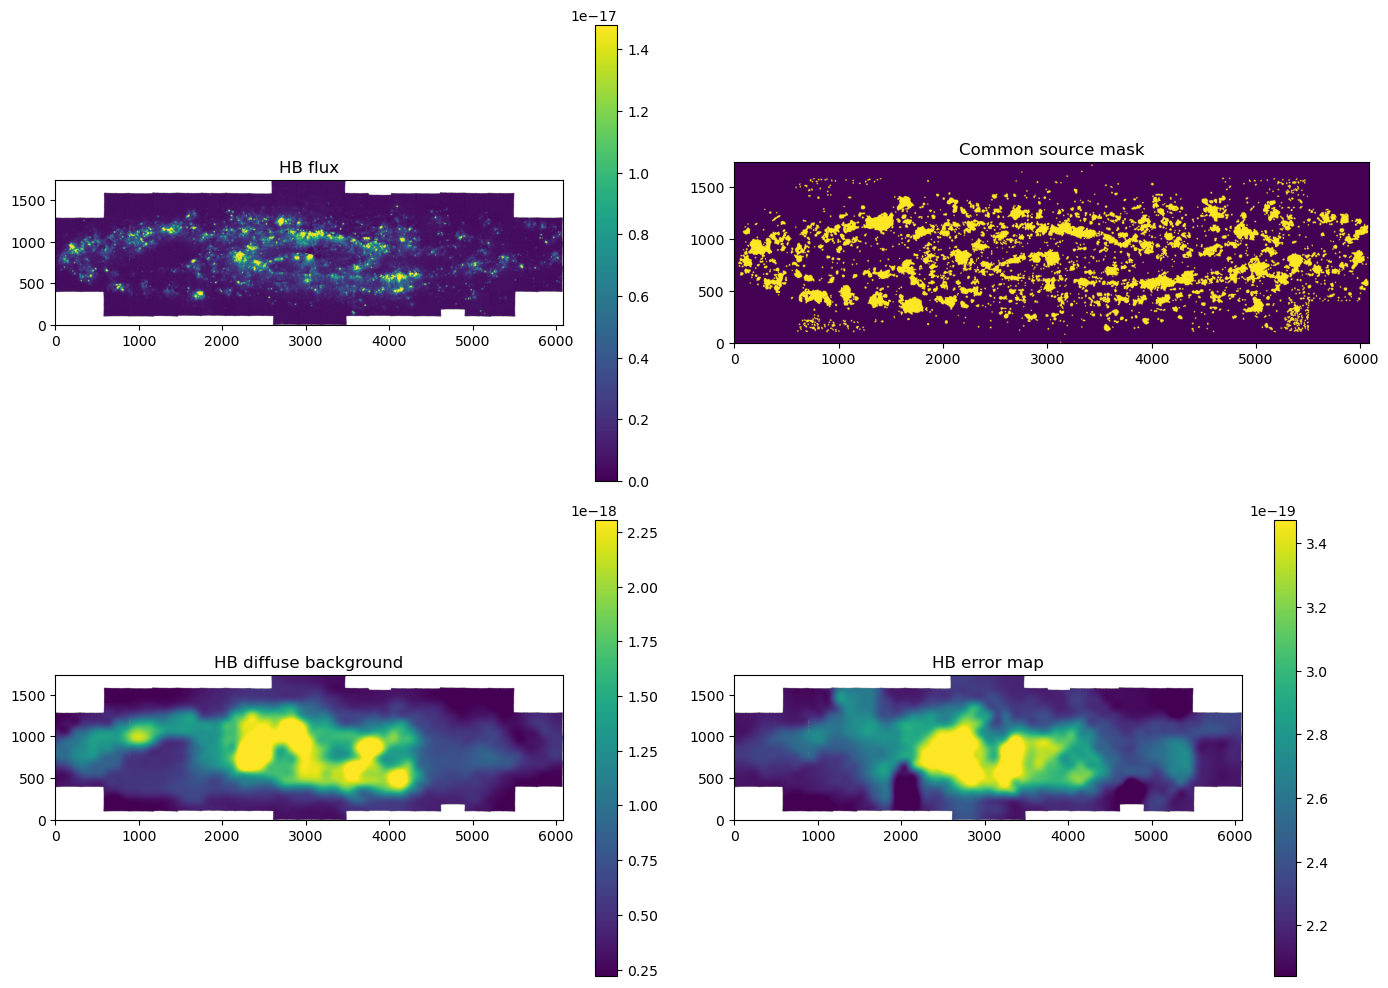

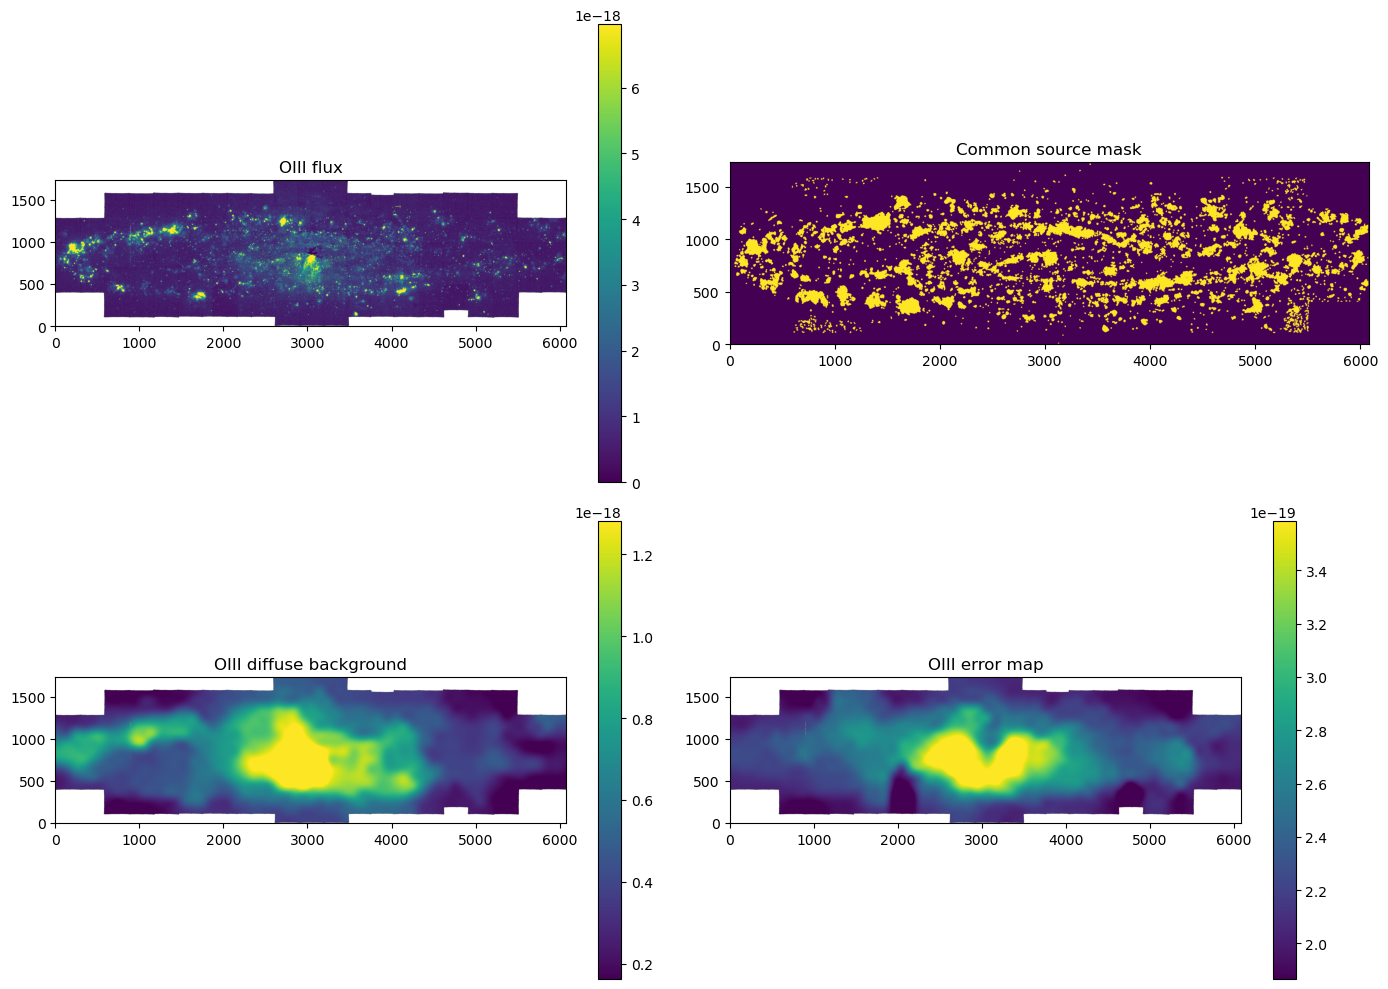

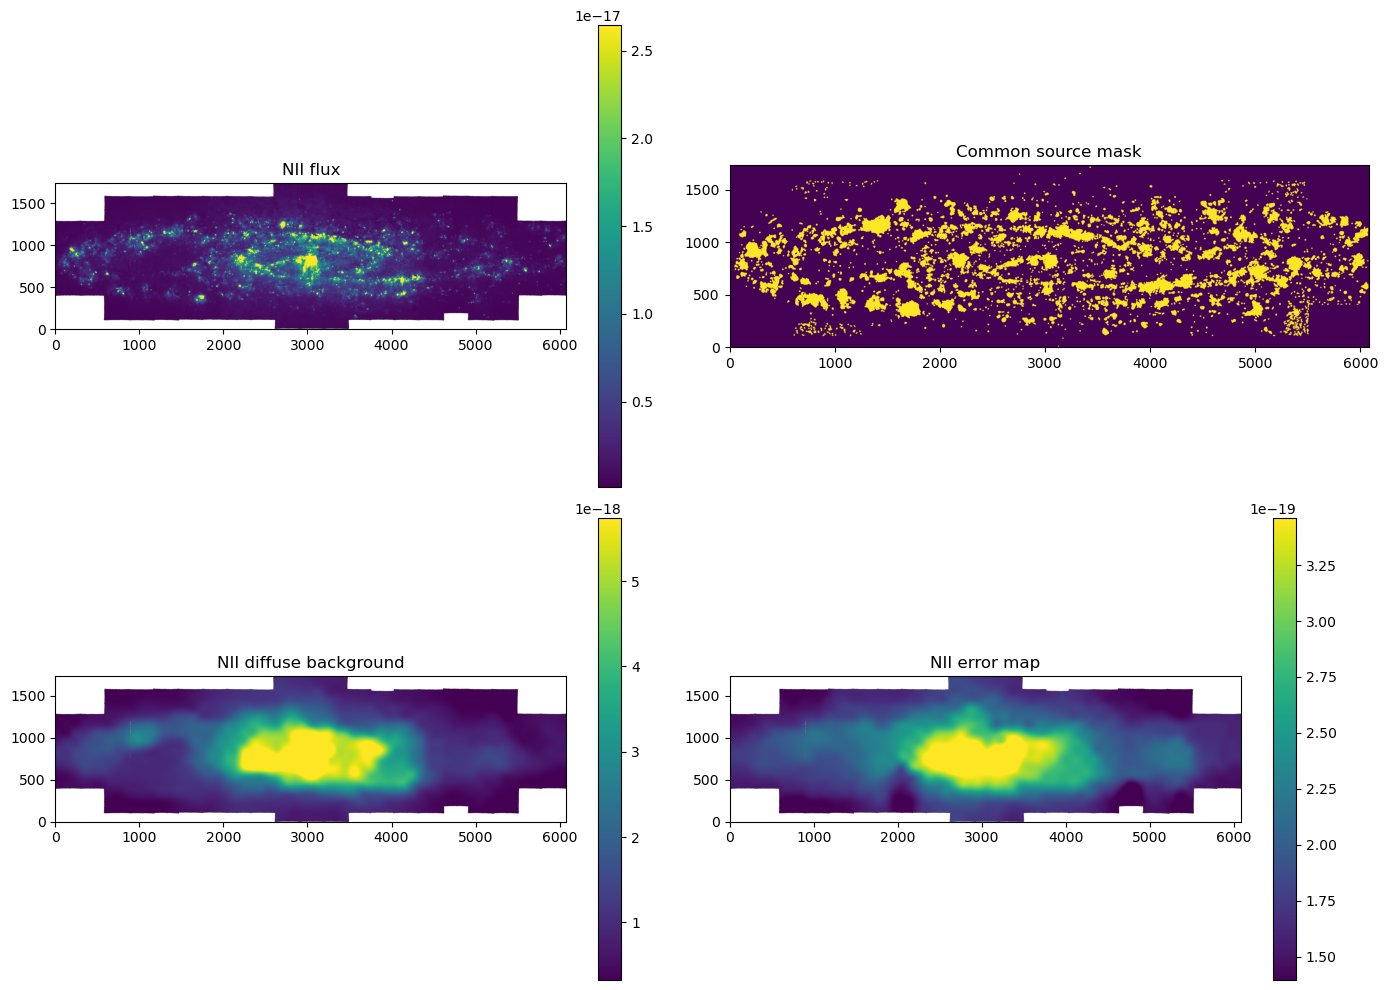

In [10]:
# =========================================================
# 7. Plot one channel at a time
# =========================================================

def plot_channel(name):

    flux = flux_maps[name]
    bkg = background_maps[name]
    err = error_maps[name]
    coverage = coverage_masks[name]


    valid_flux = (
        ~coverage
        & np.isfinite(flux)
    )

    valid_bkg = (
        ~coverage
        & np.isfinite(bkg)
    )

    valid_err = (
        ~coverage
        & np.isfinite(err)
    )


    fmin, fmax = np.nanpercentile(
        flux[valid_flux],
        [5, 99]
    )

    bmin, bmax = np.nanpercentile(
        bkg[valid_bkg],
        [5, 95]
    )

    emin, emax = np.nanpercentile(
        err[valid_err],
        [5, 95]
    )


    fig, ax = plt.subplots(
        2,
        2,
        figsize=(14, 10)
    )


    # Flux
    im = ax[0, 0].imshow(
        flux,
        origin="lower",
        vmin=fmin,
        vmax=fmax
    )

    ax[0, 0].set_title(
        f"{name.upper()} flux"
    )

    fig.colorbar(
        im,
        ax=ax[0, 0]
    )


    # Source mask
    ax[0, 1].imshow(
        source_mask,
        origin="lower"
    )

    ax[0, 1].set_title(
        "Common source mask"
    )


    # Background
    im = ax[1, 0].imshow(
        bkg,
        origin="lower",
        vmin=bmin,
        vmax=bmax
    )

    ax[1, 0].set_title(
        f"{name.upper()} diffuse background"
    )

    fig.colorbar(
        im,
        ax=ax[1, 0]
    )


    # Error
    im = ax[1, 1].imshow(
        err,
        origin="lower",
        vmin=emin,
        vmax=emax
    )

    ax[1, 1].set_title(
        f"{name.upper()} error map"
    )

    fig.colorbar(
        im,
        ax=ax[1, 1]
    )


    plt.tight_layout()
    plt.savefig(f"bkg_{name}.png")
    plt.show()


plot_channel("ha")
plot_channel("hb")
plot_channel("oiii")
plot_channel("nii")


In [11]:
# =========================================================
# 8. Save
# =========================================================

np.savez(
    "NGC253_background_and_errors.npz",

    ha_background=background_maps["ha"],
    hb_background=background_maps["hb"],
    oiii_background=background_maps["oiii"],
    nii_background=background_maps["nii"],

    ha_error=error_maps["ha"],
    hb_error=error_maps["hb"],
    oiii_error=error_maps["oiii"],
    nii_error=error_maps["nii"],

    source_mask=source_mask,
    common_valid=common_valid,
)


print(
    "Saved: NGC253_background_and_errors.npz"
)


Saved: NGC253_background_and_errors.npz
